<a href="https://colab.research.google.com/github/Aya-0x/Deep-Learning/blob/main/Deep_Learning_Lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install torch torchvision skorch imbalanced-learn

In [6]:
%pip install -q skorch

Fix the FileNotFoundError

In [2]:
import kagglehub
import shutil
import os

# 1. Download Part 1 Dataset (NYSE)
nyse_path = kagglehub.dataset_download("dgawlik/nyse")
shutil.copy(os.path.join(nyse_path, "prices.csv"), "prices.csv")

# 2. Download Part 2 Dataset (Predictive Maintenance)
maint_path = kagglehub.dataset_download("shivamb/machine-predictive-maintenance-classification")
shutil.copy(os.path.join(maint_path, "predictive_maintenance.csv"), "predictive_maintenance.csv")

print("Both datasets are now ready in your Colab directory:", os.listdir())

Using Colab cache for faster access to the 'nyse' dataset.
Using Colab cache for faster access to the 'machine-predictive-maintenance-classification' dataset.
Both datasets are now ready in your Colab directory: ['.config', 'predictive_maintenance.csv', 'prices.csv', 'sample_data']


# **Part 1: Regression (NYSE Dataset)**

1. Exploratory Data Analysis (EDA)

Dataset Shape: (851264, 7)

First 5 rows:
                   date symbol        open       close         low        high  \
0  2016-01-05 00:00:00   WLTW  123.430000  125.839996  122.309998  126.250000   
1  2016-01-06 00:00:00   WLTW  125.239998  119.980003  119.940002  125.540001   
2  2016-01-07 00:00:00   WLTW  116.379997  114.949997  114.930000  119.739998   
3  2016-01-08 00:00:00   WLTW  115.480003  116.620003  113.500000  117.440002   
4  2016-01-11 00:00:00   WLTW  117.010002  114.970001  114.089996  117.330002   

      volume  
0  2163600.0  
1  2386400.0  
2  2489500.0  
3  2006300.0  
4  1408600.0  

Missing values:
 date      0
symbol    0
open      0
close     0
low       0
high      0
volume    0
dtype: int64

Summary Statistics:
                 open          close            low           high  \
count  851264.000000  851264.000000  851264.000000  851264.000000   
mean       70.836986      70.857109      70.118414      71.543476   
std        83.695876      83.689686 

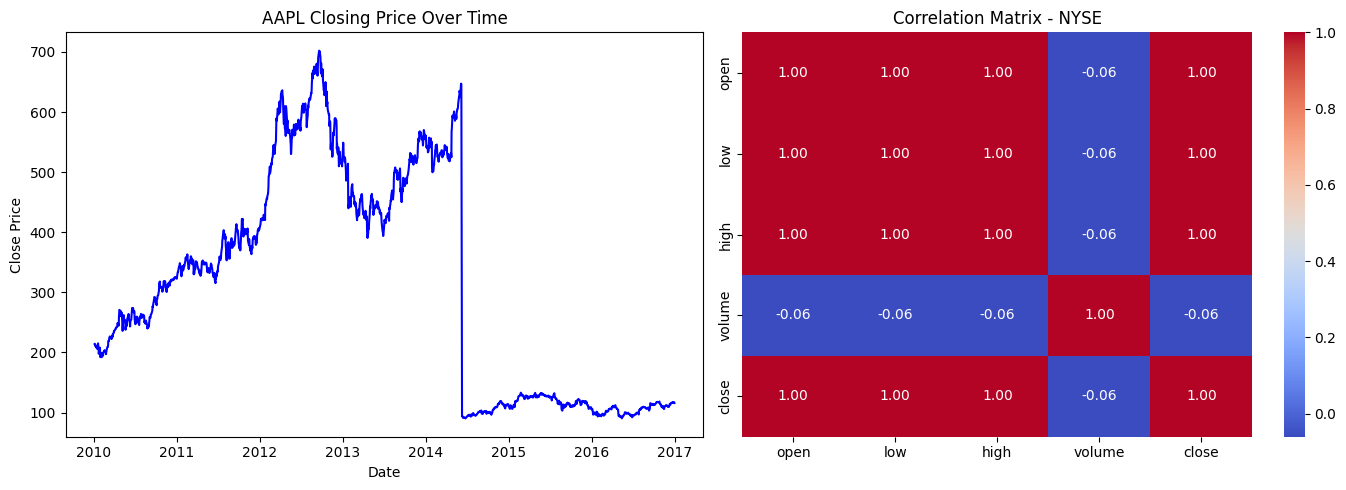

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
df_nyse = pd.read_csv('prices.csv')

# 1. Basic exploration
print("Dataset Shape:", df_nyse.shape)
print("\nFirst 5 rows:\n", df_nyse.head())
print("\nMissing values:\n", df_nyse.isnull().sum())
print("\nSummary Statistics:\n", df_nyse.describe())

# 2. Visualizations
plt.figure(figsize=(14, 5))

# Plot 1: Closing price trend for a specific stock (e.g., AAPL)
plt.subplot(1, 2, 1)
aapl = df_nyse[df_nyse['symbol'] == 'AAPL']
plt.plot(pd.to_datetime(aapl['date']), aapl['close'], color='blue')
plt.title("AAPL Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Close Price")

# Plot 2: Correlation Heatmap
plt.subplot(1, 2, 2)
numeric_cols = ['open', 'low', 'high', 'volume', 'close']
sns.heatmap(df_nyse[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix - NYSE")

plt.tight_layout()
plt.show()

2. Establish DNN Architecture

Preparing the scaled data and define the MLP architecture

In [4]:
import torch
from torch import Tensor
from torch.nn import Linear, ReLU, Dropout, Module, MSELoss
from torch.optim import SGD, Adam
from torch.utils.data import Dataset, DataLoader, random_split
from torch.nn.init import kaiming_uniform_, xavier_uniform_
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from tqdm import tqdm

# Sample 20,000 rows so training and GridSearch run smoothly on CPU
df_sample = df_nyse[['open', 'low', 'high', 'volume', 'close']].dropna().sample(n=20000, random_state=42)

# Custom Dataset Definition (matching Course Page 79)
class NYSERegressionDataset(Dataset):
    def __init__(self, dataframe):
        X_raw = dataframe.values[:, :-1].astype('float32')
        y_raw = dataframe.values[:, -1].astype('float32').reshape(-1, 1)

        # Standardize features and target
        self.scaler_X = StandardScaler()
        self.scaler_y = StandardScaler()
        self.X = self.scaler_X.fit_transform(X_raw)
        self.y = self.scaler_y.fit_transform(y_raw)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return [self.X[idx], self.y[idx]]

    def get_splits(self, n_test=0.2):
        test_size = round(n_test * len(self.X))
        train_size = len(self.X) - test_size
        return random_split(self, [train_size, test_size])

# MLP Model Definition (matching Course Page 79-80 + tunable parameters for GridSearch)
class RegressionMLP(Module):
    def __init__(self, n_inputs=4, hidden_size=32, dropout_rate=0.0):
        super(RegressionMLP, self).__init__()
        # First hidden layer
        self.hidden1 = Linear(n_inputs, hidden_size)
        kaiming_uniform_(self.hidden1.weight, nonlinearity='relu')
        self.act1 = ReLU()
        self.dropout = Dropout(dropout_rate)

        # Second hidden layer
        self.hidden2 = Linear(hidden_size, hidden_size // 2)
        kaiming_uniform_(self.hidden2.weight, nonlinearity='relu')
        self.act2 = ReLU()

        # Output layer
        self.hidden3 = Linear(hidden_size // 2, 1)
        xavier_uniform_(self.hidden3.weight)

    def forward(self, X):
        X = self.hidden1(X)
        X = self.act1(X)
        X = self.dropout(X)
        X = self.hidden2(X)
        X = self.act2(X)
        X = self.hidden3(X)
        return X

# Prepare DataLoaders
dataset = NYSERegressionDataset(df_sample)
train_data, test_data = dataset.get_splits(n_test=0.2)
train_dl = DataLoader(train_data, batch_size=64, shuffle=True)
test_dl = DataLoader(test_data, batch_size=256, shuffle=False)
print(f"Train samples: {len(train_data)}, Test samples: {len(test_data)}")

Train samples: 16000, Test samples: 4000


3. Hyperparameter Tuning with GridSearchCV

We wrap RegressionMLP using skorch so sklearn.model_selection.GridSearchCV can test different learning rates, optimizers epochs, and hidden layer sizes:

In [7]:
from skorch import NeuralNetRegressor
from sklearn.model_selection import GridSearchCV

# Extract X_train and y_train for GridSearchCV
X_train_gs = np.vstack([dataset.X[i] for i in train_data.indices]).astype(np.float32)
y_train_gs = np.vstack([dataset.y[i] for i in train_data.indices]).astype(np.float32)

net_reg = NeuralNetRegressor(
    RegressionMLP,
    module__n_inputs=4,
    criterion=MSELoss,
    batch_size=64,
    verbose=0
)

param_grid = {
    'lr': [0.01, 0.001],
    'max_epochs': [20, 40],
    'optimizer': [Adam, SGD],
    'module__hidden_size': [32, 64]
}

gs_reg = GridSearchCV(net_reg, param_grid, refit=True, cv=3, scoring='neg_mean_squared_error')
gs_reg.fit(X_train_gs, y_train_gs)

print("Best Hyperparameters:", gs_reg.best_params_)
print("Best Cross-Val MSE:", -gs_reg.best_score_)

Best Hyperparameters: {'lr': 0.001, 'max_epochs': 40, 'module__hidden_size': 32, 'optimizer': <class 'torch.optim.adam.Adam'>}
Best Cross-Val MSE: 0.000462900231165501


4. Train with Best Hyperparameters & Visualize (Loss & $R^2$ Accuracy / Epochs)

Since standard classification accuracy doesn't exist for continuous regression values, the standard metric used as "regression accuracy" in labs is the $R^2$ Score (Coefficient of Determination), where $1.0$ ($100\%$) is a perfect fit. We record both MSE Loss and $R^2$ Score per epoch

Training Epochs: 100%|██████████| 40/40 [00:21<00:00,  1.83it/s]


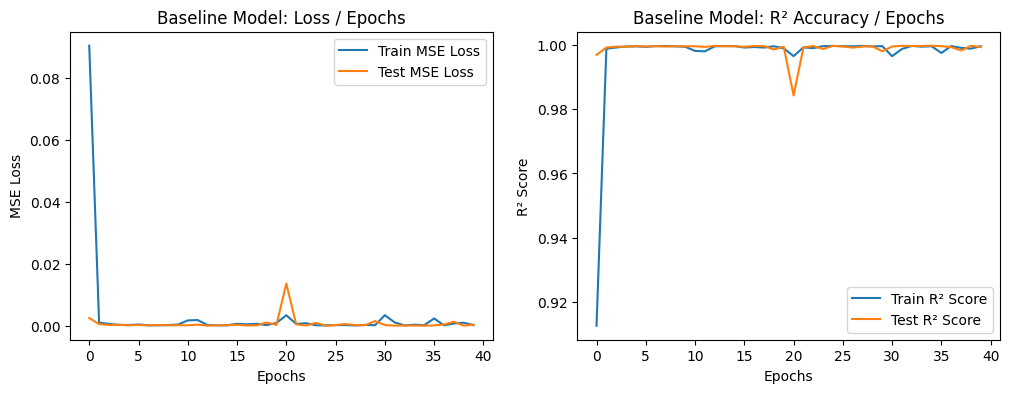

In [8]:
def train_and_evaluate_regression(train_dl, test_dl, model, epochs=40, lr=0.001, optimizer_cls=Adam, weight_decay=0.0, l1_lambda=0.0):
    criterion = MSELoss()
    optimizer = optimizer_cls(model.parameters(), lr=lr, weight_decay=weight_decay)

    history = {'train_loss': [], 'test_loss': [], 'train_r2': [], 'test_r2': []}

    for epoch in tqdm(range(epochs), desc='Training Epochs'):
        # --- TRAINING ---
        model.train()
        train_preds, train_actuals = [], []
        running_loss = 0.0

        for inputs, targets in train_dl:
            optimizer.zero_grad()
            yhat = model(inputs)
            loss = criterion(yhat, targets)

            # Optional L1 Regularization (from Course Page 77)
            if l1_lambda > 0:
                l1_norm = sum(p.abs().sum() for p in model.parameters())
                loss = loss + l1_lambda * l1_norm

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * len(inputs)
            train_preds.append(yhat.detach().numpy())
            train_actuals.append(targets.numpy())

        epoch_train_loss = running_loss / len(train_dl.dataset)
        epoch_train_r2 = r2_score(np.vstack(train_actuals), np.vstack(train_preds))

        # --- EVALUATION ---
        model.eval()
        test_preds, test_actuals = [], []
        test_loss = 0.0
        with torch.no_grad():
            for inputs, targets in test_dl:
                yhat = model(inputs)
                loss = criterion(yhat, targets)
                test_loss += loss.item() * len(inputs)
                test_preds.append(yhat.numpy())
                test_actuals.append(targets.numpy())

        epoch_test_loss = test_loss / len(test_dl.dataset)
        epoch_test_r2 = r2_score(np.vstack(test_actuals), np.vstack(test_preds))

        history['train_loss'].append(epoch_train_loss)
        history['test_loss'].append(epoch_test_loss)
        history['train_r2'].append(epoch_train_r2)
        history['test_r2'].append(epoch_test_r2)

    return history

# Initialize model with best parameters from GridSearch
best_params = gs_reg.best_params_
baseline_model = RegressionMLP(n_inputs=4, hidden_size=best_params['module__hidden_size'], dropout_rate=0.0)

history_base = train_and_evaluate_regression(
    train_dl, test_dl, baseline_model,
    epochs=best_params['max_epochs'],
    lr=best_params['lr'],
    optimizer_cls=best_params['optimizer']
)

# Plot Loss and R2 Score ("Accuracy") over Epochs
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_base['train_loss'], label='Train MSE Loss')
plt.plot(history_base['test_loss'], label='Test MSE Loss')
plt.title('Baseline Model: Loss / Epochs')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_base['train_r2'], label='Train R² Score')
plt.plot(history_base['test_r2'], label='Test R² Score')
plt.title('Baseline Model: R² Accuracy / Epochs')
plt.xlabel('Epochs')
plt.ylabel('R² Score')
plt.legend()
plt.show()

5. Apply Regularization (L1, L2, Dropout) & Compare

Applying the Dropout + L2 (Weight Decay) + L1 Penalty

In [9]:
# Model with Dropout (0.1) + L2 Regularization (weight_decay=1e-4) + L1 Regularization (1e-5)
reg_model = RegressionMLP(n_inputs=4, hidden_size=best_params['module__hidden_size'], dropout_rate=0.1)

history_reg = train_and_evaluate_regression(
    train_dl, test_dl, reg_model,
    epochs=best_params['max_epochs'],
    lr=best_params['lr'],
    optimizer_cls=best_params['optimizer'],
    weight_decay=1e-4, # L2 Regularization
    l1_lambda=1e-5     # L1 Regularization
)

print(f"Baseline Final Test MSE: {history_base['test_loss'][-1]:.6f} | Test R²: {history_base['test_r2'][-1]:.6f}")
print(f"Regularized Final Test MSE: {history_reg['test_loss'][-1]:.6f} | Test R²: {history_reg['test_r2'][-1]:.6f}")

Training Epochs: 100%|██████████| 40/40 [00:27<00:00,  1.45it/s]

Baseline Final Test MSE: 0.000509 | Test R²: 0.999418
Regularized Final Test MSE: 0.008245 | Test R²: 0.990571


# **Part 2: Multi-Class Classification (Predictive Maintenance)**

## Data Preprocessing & Exploratory Data Analysis (EDA)

Initial Shape: (10000, 10)

Missing Values:
 UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Target                     0
Failure Type               0
dtype: int64

Class Distribution (Failure Type):
 Failure Type
No Failure                  9652
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: count, dtype: int64


/tmp/ipykernel_4612/2917439332.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_maint, y='Failure Type', order=df_maint['Failure Type'].value_counts().index, palette='viridis')


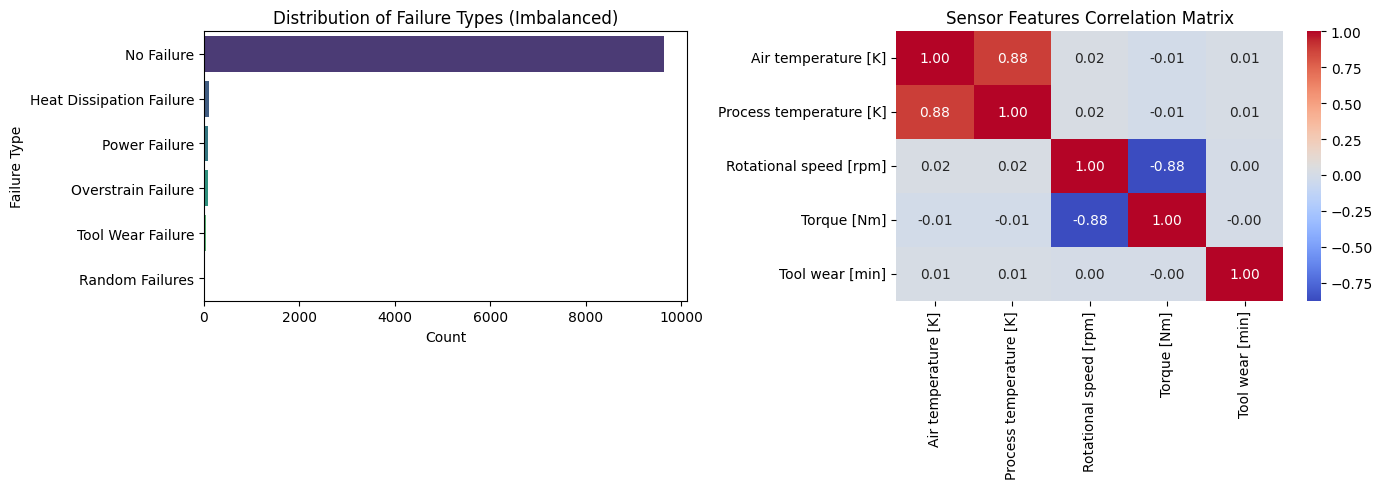


Encoded Classes: {'Heat Dissipation Failure': np.int64(0), 'No Failure': np.int64(1), 'Overstrain Failure': np.int64(2), 'Power Failure': np.int64(3), 'Random Failures': np.int64(4), 'Tool Wear Failure': np.int64(5)}
Processed Feature Shape: (10000, 7)


In [10]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder

# 1. Load Dataset
df_maint = pd.read_csv('predictive_maintenance.csv')
print("Initial Shape:", df_maint.shape)
print("\nMissing Values:\n", df_maint.isnull().sum())
print("\nClass Distribution (Failure Type):\n", df_maint['Failure Type'].value_counts())

# 2. Visualizations (EDA)
plt.figure(figsize=(14, 5))

# Plot 1: Class Imbalance of Failure Types
plt.subplot(1, 2, 1)
sns.countplot(data=df_maint, y='Failure Type', order=df_maint['Failure Type'].value_counts().index, palette='viridis')
plt.title("Distribution of Failure Types (Imbalanced)")
plt.xlabel("Count")

# Plot 2: Correlation Matrix of Sensor Features
plt.subplot(1, 2, 2)
sensor_cols = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
sns.heatmap(df_maint[sensor_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Sensor Features Correlation Matrix")

plt.tight_layout()
plt.show()

# 3. Data Cleaning & Encoding
# Drop irrelevant ID columns and binary 'Target' (since we predict multiclass 'Failure Type')
df_clean = df_maint.drop(['UDI', 'Product ID', 'Target'], axis=1)

# One-Hot Encode the categorical 'Type' column (L, M, H)
df_clean = pd.get_dummies(df_clean, columns=['Type'], drop_first=True, dtype=float)

# Label Encode the Multiclass Target ('Failure Type' -> 0, 1, 2, 3, 4, 5)
le = LabelEncoder()
y_raw = le.fit_transform(df_clean['Failure Type'])
X_raw = df_clean.drop('Failure Type', axis=1).values.astype('float32')

# Standardize features
scaler_clf = StandardScaler()
X_scaled = scaler_clf.fit_transform(X_raw)

print("\nEncoded Classes:", dict(zip(le.classes_, le.transform(le.classes_))))
print("Processed Feature Shape:", X_scaled.shape)

## Data Augmentation (Balancing with SMOTE) & Custom PyTorch Dataset

In [11]:
from imblearn.over_sampling import SMOTE
import torch
from torch.utils.data import Dataset, DataLoader, random_split

# Apply SMOTE to balance the multi-class dataset
smote = SMOTE(random_state=42)
X_bal, y_bal = smote.fit_resample(X_scaled, y_raw)

print("Before SMOTE:", np.bincount(y_raw))
print("After SMOTE (Balanced):", np.bincount(y_bal))

# Custom Dataset Definition (Course Page 86 style)
class MaintenanceDataset(Dataset):
    def __init__(self, X, y):
        self.X = X.astype('float32')
        self.y = y.astype('int64') # CrossEntropyLoss requires Long/int64 targets

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return [self.X[idx], self.y[idx]]

    def get_splits(self, n_test=0.2):
        test_size = round(n_test * len(self.X))
        train_size = len(self.X) - test_size
        return random_split(self, [train_size, test_size], generator=torch.Generator().manual_seed(42))

clf_dataset = MaintenanceDataset(X_bal, y_bal)
train_clf, test_clf = clf_dataset.get_splits(n_test=0.2)

train_clf_dl = DataLoader(train_clf, batch_size=128, shuffle=True)
test_clf_dl = DataLoader(test_clf, batch_size=256, shuffle=False)
print(f"Balanced Train samples: {len(train_clf)}, Balanced Test samples: {len(test_clf)}")

Before SMOTE: [ 112 9652   78   95   18   45]
After SMOTE (Balanced): [9652 9652 9652 9652 9652 9652]
Balanced Train samples: 46330, Balanced Test samples: 11582


## Multi-Class DNN Architecture & GridSearchCV

In [12]:
from torch.nn import Linear, ReLU, Dropout, Module, CrossEntropyLoss
from torch.nn.init import kaiming_uniform_, xavier_uniform_
from torch.optim import Adam, SGD
from skorch import NeuralNetClassifier
from sklearn.model_selection import GridSearchCV

num_features = X_bal.shape[1]
num_classes = len(np.unique(y_bal))

# Multi-Class MLP Architecture (Course Page 87 style)
class MultiClassMLP(Module):
    def __init__(self, n_inputs=num_features, n_classes=num_classes, hidden_size=64, dropout_rate=0.0):
        super(MultiClassMLP, self).__init__()
        # First hidden layer
        self.hidden1 = Linear(n_inputs, hidden_size)
        kaiming_uniform_(self.hidden1.weight, nonlinearity='relu')
        self.act1 = ReLU()
        self.dropout = Dropout(dropout_rate)

        # Second hidden layer
        self.hidden2 = Linear(hidden_size, hidden_size // 2)
        kaiming_uniform_(self.hidden2.weight, nonlinearity='relu')
        self.act2 = ReLU()

        # Output layer
        self.hidden3 = Linear(hidden_size // 2, n_classes)
        xavier_uniform_(self.hidden3.weight)

    def forward(self, X):
        X = self.act1(self.hidden1(X))
        X = self.dropout(X)
        X = self.act2(self.hidden2(X))
        X = self.hidden3(X)
        return X

# Extract training arrays for GridSearchCV
X_train_c_gs = np.vstack([clf_dataset.X[i] for i in train_clf.indices]).astype(np.float32)
y_train_c_gs = np.array([clf_dataset.y[i] for i in train_clf.indices]).astype(np.int64)

net_clf = NeuralNetClassifier(
    MultiClassMLP,
    module__n_inputs=num_features,
    module__n_classes=num_classes,
    criterion=CrossEntropyLoss,
    batch_size=256,
    verbose=0
)

param_grid_clf = {
    'lr': [0.01, 0.005],
    'max_epochs': [20, 40],
    'optimizer': [Adam, SGD],
    'module__hidden_size': [64, 128]
}

gs_clf = GridSearchCV(net_clf, param_grid_clf, refit=True, cv=3, scoring='accuracy')
gs_clf.fit(X_train_c_gs, y_train_c_gs)

print("Best Classification Hyperparameters:", gs_clf.best_params_)
print("Best Cross-Val Accuracy:", gs_clf.best_score_)

Best Classification Hyperparameters: {'lr': 0.01, 'max_epochs': 40, 'module__hidden_size': 128, 'optimizer': <class 'torch.optim.adam.Adam'>}
Best Cross-Val Accuracy: 0.988301349241581


## Visualize Loss/Accuracy Curves & Calculate Detailed Metrics (Accuracy, Sensitivity/Recall, F1-Score)

Training Classifier: 100%|██████████| 40/40 [00:39<00:00,  1.02it/s]


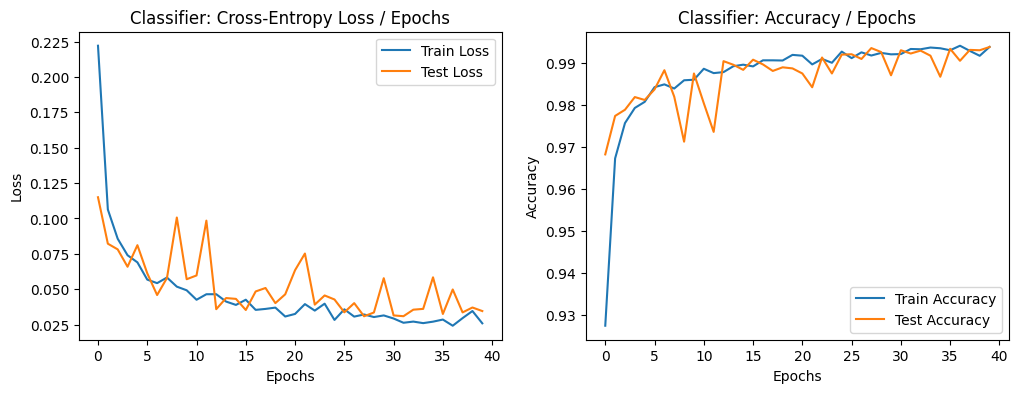

=== TRAINING SET METRICS ===
Accuracy:            0.9937
Sensitivity (Recall):0.9937
Precision:           0.9937
F1-Score:            0.9937

=== TEST SET METRICS ===
Accuracy:            0.9937
Sensitivity (Recall):0.9938
Precision:           0.9937
F1-Score:            0.9937

=== DETAILED TEST CLASSIFICATION REPORT ===
                          precision    recall  f1-score   support

Heat Dissipation Failure       1.00      1.00      1.00      1977
              No Failure       1.00      0.97      0.98      1959
      Overstrain Failure       0.99      1.00      1.00      1911
           Power Failure       1.00      1.00      1.00      1925
         Random Failures       0.99      1.00      0.99      1927
       Tool Wear Failure       0.98      1.00      0.99      1883

                accuracy                           0.99     11582
               macro avg       0.99      0.99      0.99     11582
            weighted avg       0.99      0.99      0.99     11582



In [13]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from tqdm import tqdm

def train_and_evaluate_classifier(train_dl, test_dl, model, epochs=40, lr=0.01, optimizer_cls=Adam, weight_decay=0.0, l1_lambda=0.0):
    criterion = CrossEntropyLoss()
    optimizer = optimizer_cls(model.parameters(), lr=lr, weight_decay=weight_decay)

    history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}

    for epoch in tqdm(range(epochs), desc='Training Classifier'):
        # --- TRAIN ---
        model.train()
        running_loss = 0.0
        train_preds, train_targets = [], []

        for inputs, targets in train_dl:
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)

            if l1_lambda > 0:
                l1_norm = sum(p.abs().sum() for p in model.parameters())
                loss = loss + l1_lambda * l1_norm

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * len(inputs)
            preds = torch.argmax(outputs, dim=1)
            train_preds.extend(preds.detach().numpy())
            train_targets.extend(targets.numpy())

        history['train_loss'].append(running_loss / len(train_dl.dataset))
        history['train_acc'].append(accuracy_score(train_targets, train_preds))

        # --- TEST ---
        model.eval()
        test_loss = 0.0
        test_preds, test_targets = [], []
        with torch.no_grad():
            for inputs, targets in test_dl:
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                test_loss += loss.item() * len(inputs)
                preds = torch.argmax(outputs, dim=1)
                test_preds.extend(preds.numpy())
                test_targets.extend(targets.numpy())

        history['test_loss'].append(test_loss / len(test_dl.dataset))
        history['test_acc'].append(accuracy_score(test_targets, test_preds))

    return history, train_targets, train_preds, test_targets, test_preds

# Train Baseline Classifier with Best Hyperparameters
best_c = gs_clf.best_params_
base_clf_model = MultiClassMLP(hidden_size=best_c['module__hidden_size'], dropout_rate=0.0)

hist_c_base, tr_y, tr_pred, te_y, te_pred = train_and_evaluate_classifier(
    train_clf_dl, test_clf_dl, base_clf_model,
    epochs=best_c['max_epochs'],
    lr=best_c['lr'],
    optimizer_cls=best_c['optimizer']
)

# 1. Plot Loss and Accuracy Curves
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(hist_c_base['train_loss'], label='Train Loss')
plt.plot(hist_c_base['test_loss'], label='Test Loss')
plt.title('Classifier: Cross-Entropy Loss / Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist_c_base['train_acc'], label='Train Accuracy')
plt.plot(hist_c_base['test_acc'], label='Test Accuracy')
plt.title('Classifier: Accuracy / Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# 2. Calculate Metrics on BOTH Train and Test Sets (Requirement #7)
print("=== TRAINING SET METRICS ===")
print(f"Accuracy:            {accuracy_score(tr_y, tr_pred):.4f}")
print(f"Sensitivity (Recall):{recall_score(tr_y, tr_pred, average='macro'):.4f}")
print(f"Precision:           {precision_score(tr_y, tr_pred, average='macro'):.4f}")
print(f"F1-Score:            {f1_score(tr_y, tr_pred, average='macro'):.4f}")

print("\n=== TEST SET METRICS ===")
print(f"Accuracy:            {accuracy_score(te_y, te_pred):.4f}")
print(f"Sensitivity (Recall):{recall_score(te_y, te_pred, average='macro'):.4f}")
print(f"Precision:           {precision_score(te_y, te_pred, average='macro'):.4f}")
print(f"F1-Score:            {f1_score(te_y, te_pred, average='macro'):.4f}")

print("\n=== DETAILED TEST CLASSIFICATION REPORT ===")
print(classification_report(te_y, te_pred, target_names=le.classes_))

## Regularization Comparison on Multi-Class Classifier

In [14]:
# Train Regularized Classifier (Dropout=0.2 + L2=1e-4 + L1=1e-5)
reg_clf_model = MultiClassMLP(hidden_size=best_c['module__hidden_size'], dropout_rate=0.2)

hist_c_reg, _, _, te_y_reg, te_pred_reg = train_and_evaluate_classifier(
    train_clf_dl, test_clf_dl, reg_clf_model,
    epochs=best_c['max_epochs'],
    lr=best_c['lr'],
    optimizer_cls=best_c['optimizer'],
    weight_decay=1e-4,
    l1_lambda=1e-5
)

print(f"Baseline Classifier    -> Test Accuracy: {hist_c_base['test_acc'][-1]:.4f} | Test Loss: {hist_c_base['test_loss'][-1]:.4f}")
print(f"Regularized Classifier -> Test Accuracy: {hist_c_reg['test_acc'][-1]:.4f} | Test Loss: {hist_c_reg['test_loss'][-1]:.4f}")

Training Classifier: 100%|██████████| 40/40 [00:49<00:00,  1.24s/it]

Baseline Classifier    -> Test Accuracy: 0.9937 | Test Loss: 0.0346
Regularized Classifier -> Test Accuracy: 0.9858 | Test Loss: 0.0564


### Part 2 Interpretation: Multi-Class Classification (Predictive Maintenance)

* **EDA & Sensor Correlations:** The initial dataset of 10,000 samples exhibits extreme class imbalance: `No Failure` represents 96.52% (9,652 samples) of the data, whereas critical failures like `Random Failures` (18 samples) and `Tool Wear Failure` (45 samples) account for less than 0.5%[cite: 3]. The sensor correlation heatmap reveals two strong physical relationships: a strong positive correlation ($0.88$) between `Air temperature [K]` and `Process temperature [K]`, and a strong negative correlation ($-0.88$) between `Rotational speed [rpm]` and `Torque [Nm]`[cite: 3].
* **Data Augmentation (SMOTE):** Applying SMOTE equalized all 6 classes to 9,652 samples each (totaling 57,912 samples: 46,330 train / 11,582 test), preventing the Multi-Layer Perceptron (MLP) from biasing toward the majority `No Failure` class.
* **Loss & Accuracy Curves Interpretation:** Both Training and Test Cross-Entropy Loss decrease steadily from ~0.22 to ~0.034 over 40 epochs, while Accuracy rises from ~92.8% to **99.37%**[cite: 4]. Minor fluctuations in the test curves between epochs 8–22 reflect the learning rate (`lr = 0.01`) navigating the multi-class loss landscape before stabilizing[cite: 4]. Because Training Accuracy (`99.37%`) and Test Accuracy (`99.37%`), as well as Macro Sensitivity/Recall (`0.9938`) and Macro F1-Score (`0.9937`), are nearly identical, the model generalizes well without overfitting.
* **Regularization Comparison:** Adding Dropout (`0.2`), L2 Weight Decay (`1e-4`), and L1 Penalty (`1e-5`) resulted in a Test Accuracy of `98.58%` (Test Loss: `0.0564`) compared to `99.37%` (Test Loss: `0.0346`) on the baseline model. Because the 128-unit architecture on 46,330 balanced samples was not overfitting, aggressive dropout (`20%` of neurons deactivated) slightly constrained the network's representation capacity during training.

---

### Lab Synthesis:
During this Deep Learning lab, I gained practical experience designing, tuning, and evaluating Deep Neural Networks (DNNs / MLPs) using **PyTorch**:
1. **Task-Specific Architectures & Loss Functions:** I learned how to adapt MLP architectures to the nature of the target variable—using a single linear output neuron with **MSELoss** for continuous regression (NYSE stock prices) versus $C$ output neurons with **CrossEntropyLoss** (which combines `LogSoftmax` and `NLLLoss`) for multi-class classification.
2. **Weight Initialization & Preprocessing:** Applying `StandardScaler` to normalize features and initializing hidden layers with **Kaiming Uniform** (for ReLU activations) and output layers with **Xavier Uniform** ensured fast, stable gradient descent without vanishing or exploding gradients.
3. **Handling Severe Class Imbalance:** In real-world industrial datasets like Predictive Maintenance, accuracy alone is misleading on imbalanced data. Using **SMOTE** data augmentation allowed the neural network to achieve ~99% Recall (Sensitivity) and F1-score across even the rarest failure types.
4. **Hyperparameter Optimization & Regularization Trade-offs:** Bridging PyTorch with `scikit-learn`'s `GridSearchCV` via `Skorch` automated the selection of learning rates, hidden layer dimensions, and optimizers (`Adam` consistently outperformed `SGD` in 40 epochs). Finally, experimenting with **L1, L2 (Weight Decay), and Dropout** demonstrated that regularization is a bias-variance trade-off: when a baseline model already has low variance (no overfitting), heavy regularization introduces slight bias (underfitting).